# Fraud project – Step 1: find and explore the Client Insider transaction data

**Rules followed in this notebook**
- Read-only: the existing Client Insider tables are only read (`spark.table`, `SELECT`). Nothing is created, overwritten or deleted.
- No CSV exports: everything stays on Databricks.

**Source tables** (from the `Financial Transactions` notebook that builds the dashboard):

| Table | Content |
|---|---|
| `payments.default.pay_transactions` | Card transactions 2010–2011 + engineered columns used by the dashboard |
| `payments.default.pay_labels` | Fraud labels (`transaction_id`, `is_fraud`) from `train_fraud_labels.json` |
| `payments.default.pay_users` | Client profile |
| `payments.default.pay_cards` | Card profile |

In [0]:
# Libraries for Step 5 (already installed on Databricks ML runtimes; harmless if they are)
%pip install -q xgboost lightgbm

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


## 1. Find the tables

In [0]:
display(spark.sql("SHOW TABLES IN payments.default"))

database,tableName,isTemporary
default,creditcard_fraud,false
default,pay_cards,false
default,pay_labels,false
default,pay_transactions,false
default,pay_users,false
default,pay_users_enriched,false
default,vw_city_transaction_level,false


## 2. Load the transaction table
The table has millions of rows, so we stay in Spark (no `.toPandas()` on the full table).

In [0]:
from pyspark.sql import functions as F

TX_TABLE = "payments.default.pay_transactions"
LABEL_TABLE = "payments.default.pay_labels"

df = spark.table(TX_TABLE)

n_rows = df.count()
print(f"{TX_TABLE}: {n_rows:,} rows, {len(df.columns)} columns")

payments.default.pay_transactions: 1,240,880 rows, 12 columns


## 3. Look at the data

In [0]:
display(df.limit(1000))

id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
7475327,2010-01-01 00:01:00,1556,2972,-77.0,Swipe Transaction,59935,Beulah,ND,58523.0,5499,null
7475328,2010-01-01 00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,null
7475329,2010-01-01 00:02:00,1129,102,80.0,Swipe Transaction,27092,Vista,CA,92084.0,4829,null
7475331,2010-01-01 00:05:00,430,2860,200.0,Swipe Transaction,27092,Crown Point,IN,46307.0,4829,null
7475332,2010-01-01 00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.0,5813,null
7475333,2010-01-01 00:07:00,1807,165,4.81,Swipe Transaction,20519,Bronx,NY,10464.0,5942,null
7475334,2010-01-01 00:09:00,1556,2972,77.0,Swipe Transaction,59935,Beulah,ND,58523.0,5499,null
7475335,2010-01-01 00:14:00,1684,2140,26.46,Online Transaction,39021,ONLINE,null,null,4784,null
7475336,2010-01-01 00:21:00,335,5131,261.58,Online Transaction,50292,ONLINE,null,null,7801,null
7475337,2010-01-01 00:21:00,351,1112,10.74,Swipe Transaction,3864,Flushing,NY,11355.0,5813,null


In [0]:
df.printSchema()

root
 |-- id: long (nullable = true)
 |-- date: string (nullable = true)
 |-- client_id: long (nullable = true)
 |-- card_id: long (nullable = true)
 |-- amount: double (nullable = true)
 |-- use_chip: string (nullable = true)
 |-- merchant_id: long (nullable = true)
 |-- merchant_city: string (nullable = true)
 |-- merchant_state: string (nullable = true)
 |-- zip: double (nullable = true)
 |-- mcc: long (nullable = true)
 |-- errors: string (nullable = true)



In [0]:
display(df.describe())

summary,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
count,1240880,1240880,1240880,1240880,1240880,1240880,1240880,1240880,1106058,1098838,1240880,19383
mean,8218967.071213171,null,1031.652331409967,3387.5465097350266,43.70491596286494,null,47791.496670910965,null,null,51601.71298043933,5565.034955837793,null
stddev,430220.7082988587,null,582.4443995338083,1680.8935181751608,84.99160006039585,null,25764.532655666335,null,null,29391.06946797302,872.1789772671946,null
min,7475327,2010-01-01 00:01:00,0,0,-500.0,Online Transaction,2,Aaronsburg,AK,1001.0,1711,Bad CVV
max,8966551,2010-12-31 23:56:00,1998,6034,6820.2,Swipe Transaction,100341,Zwolle,WY,99840.0,9402,Technical Glitch


In [0]:
# Missing values per column
display(df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]))

id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,0,0,0,0,0,0,0,134822,142042,0,1221497


In [0]:
# Period covered (expected: 2010 and 2011 only)
display(
    df.groupBy(F.substring("date", 1, 4).alias("year"))
      .count()
      .orderBy("year")
)

year,count
2010,1240880


In [0]:
# Categorical columns: distinct values
for c in ["use_chip", "errors", "is_online", "city_amount_level",
          "customer_frequency_level", "customer_monetary_level", "customer_boston_class"]:
    if c in df.columns:
        print(f"--- {c}")
        display(df.groupBy(c).count().orderBy(F.desc("count")).limit(20))

--- use_chip


use_chip,count
Swipe Transaction,1106058
Online Transaction,134822


--- errors


errors,count
null,1221497
Insufficient Balance,12066
Bad PIN,2985
Technical Glitch,2403
Bad Card Number,663
Bad CVV,568
Bad Expiration,511
Bad Zipcode,97
"Bad PIN,Insufficient Balance",26
"Insufficient Balance,Technical Glitch",23


## 4. Is `id` really a unique transaction ID?
If there are duplicates, the most likely cause is that the 2011 `append` cell in the source notebook was run more than once.

In [0]:
n_ids = df.select("id").distinct().count()
n_null_ids = df.filter(F.col("id").isNull()).count()

print(f"rows:          {n_rows:,}")
print(f"distinct id:   {n_ids:,}")
print(f"null id:       {n_null_ids:,}")
print("id is unique ✅" if (n_ids == n_rows and n_null_ids == 0) else "id is NOT unique ⚠️ – check duplicates below")

rows:          1,240,880
distinct id:   1,240,880
null id:       0
id is unique ✅


In [0]:
display(
    df.groupBy("id").count()
      .filter("count > 1")
      .orderBy(F.desc("count"))
      .limit(20)
)

id,count


## 5. Column dictionary

**Unique transaction ID: `id`** (verified in section 4). It is the key used in Step 8 to link scores back to transactions, and it matches `transaction_id` in `pay_labels`.

**Original columns (Kaggle "transactions-fraud-datasets")**

| Column | Meaning |
|---|---|
| `id` | **Unique transaction ID** |
| `date` | Date and time of the transaction (string, `YYYY-MM-DD HH:MM:SS`) |
| `client_id` | Client who made the transaction → `pay_users.id` |
| `card_id` | Card used → `pay_cards.id` |
| `amount` | Amount in USD (`$` removed, cast to float). Negative values = refunds/reversals |
| `use_chip` | How the card was used: swipe, chip or online |
| `merchant_id` | Merchant ID |
| `merchant_city` | Merchant city (`ONLINE` for online transactions) |
| `merchant_state` | Merchant US state, or country for foreign transactions; empty for online |
| `zip` | Merchant ZIP code; empty for online/foreign |
| `mcc` | Merchant Category Code (type of business) |
| `errors` | Error(s) raised on the transaction (e.g. bad PIN, insufficient balance); empty if none |

**Columns added for the dashboard**

| Column | Meaning |
|---|---|
| `is_online` | `ONLINE` if `merchant_city = 'ONLINE'`, otherwise `OFFLINE` |
| `city_amount_level` | Tercile of the merchant city by total amount (Low / Middle / High Level) |
| `customer_frequency_level` | Tercile of the client by number of transactions (Bassa / Media / Alta frequenza) |
| `customer_monetary_level` | Tercile of the client by total amount (Basso / Medio / Alto valore) |
| `customer_boston_class` | Client segment combining the two above (Core Champions, Frequent Value Seekers, High-Value Occasional, Watchlist, Stable) |

⚠️ The dashboard columns are computed over the **whole** 2010–2011 period, so they use information from the future relative to each transaction. Keep this in mind before using them as model features.

## 6. Is there a fraud label?

In [0]:
# 6a. Any label-like column inside the transaction table?
label_like = [c for c in df.columns if any(k in c.lower() for k in ["fraud", "label", "target", "class"])]
print("Label-like columns in pay_transactions:", label_like)
# 'customer_boston_class' is a client segment, not a fraud label.

Label-like columns in pay_transactions: []


In [0]:
# 6b. Labels are stored in a separate table
labels = spark.table(LABEL_TABLE)
labels.printSchema()

n_lab = labels.count()
n_lab_ids = labels.select("transaction_id").distinct().count()
print(f"{LABEL_TABLE}: {n_lab:,} rows, {n_lab_ids:,} distinct transaction_id")

display(labels.groupBy("is_fraud").count())

root
 |-- transaction_id: long (nullable = true)
 |-- is_fraud: string (nullable = true)

payments.default.pay_labels: 8,914,963 rows, 8,914,963 distinct transaction_id


is_fraud,count
Yes,13332
No,8901631


In [0]:
# 6c. Link labels to the dashboard transactions (in memory only, nothing is saved)
df_lab = df.join(labels, df.id == labels.transaction_id, "left")

display(df_lab.groupBy("is_fraud").count().orderBy("is_fraud"))

is_fraud,count
null,409351
No,828956
Yes,2573


In [0]:
stats = df_lab.agg(
    F.count("*").alias("n_transactions"),
    F.count("is_fraud").alias("n_labelled"),
    F.sum((F.col("is_fraud") == "Yes").cast("int")).alias("n_fraud"),
).first()

coverage = stats.n_labelled / stats.n_transactions * 100
fraud_pct_labelled = stats.n_fraud / stats.n_labelled * 100
fraud_pct_all = stats.n_fraud / stats.n_transactions * 100

print(f"Transactions in pay_transactions : {stats.n_transactions:,}")
print(f"  with a label                   : {stats.n_labelled:,}  ({coverage:.2f}%)")
print(f"  labelled as fraud ('Yes')      : {stats.n_fraud:,}")
print(f"Fraud % on labelled transactions : {fraud_pct_labelled:.3f}%")
print(f"Fraud % on all transactions      : {fraud_pct_all:.3f}%")

Transactions in pay_transactions : 1,240,880
  with a label                   : 831,529  (67.01%)
  labelled as fraud ('Yes')      : 2,573
Fraud % on labelled transactions : 0.309%
Fraud % on all transactions      : 0.207%


**Note:** `pay_users.fraud_risk_level` (Critical / Suspicious / Normal) is **not** a fraud label: it is a rule built from debt and income. It must not be used as the target.

# Step 2: new features to spot fraud

All features are built with Spark window functions (the data is too large for pandas).
**Anti-leakage rule:** every window is ordered by time and only looks at the **current or earlier** transactions of the same client, never later ones.
The result stays in memory as `df_feat`: no table is written.

Real column names: client = `client_id`, merchant = `merchant_id`, date = `date` (string → timestamp `ts`).

In [0]:
from pyspark.sql import Window

# Parse the date once
base = (
    df.withColumn("ts", F.to_timestamp("date"))
      .withColumn("ts_sec", F.col("ts").cast("long"))
      # "place" = country/US state for physical transactions, ONLINE for online ones
      .withColumn(
          "place",
          F.when(F.col("merchant_city") == "ONLINE", F.lit("ONLINE"))
           .otherwise(F.coalesce(F.col("merchant_state"), F.lit("UNKNOWN")))
      )
)

print("Unparsed dates:", base.filter(F.col("ts").isNull()).count())

Unparsed dates: 0


In [0]:
# Windows — all ordered by time, ties broken by id
w_client      = Window.partitionBy("client_id").orderBy("ts_sec", "id")
w_client_past = w_client.rowsBetween(Window.unboundedPreceding, -1)            # strictly previous transactions
w_last_1h     = Window.partitionBy("client_id").orderBy("ts_sec").rangeBetween(-3600, 0)
w_last_24h    = Window.partitionBy("client_id").orderBy("ts_sec").rangeBetween(-86400, 0)
w_cl_merchant = Window.partitionBy("client_id", "merchant_id").orderBy("ts_sec", "id")
w_cl_place    = Window.partitionBy("client_id", "place").orderBy("ts_sec", "id")

df_feat = (
    base
    # --- time of the transaction
    .withColumn("tx_hour", F.hour("ts"))
    .withColumn("tx_weekday", (F.dayofweek("ts") + 5) % 7)                      # 0 = Monday … 6 = Sunday
    .withColumn("is_night", F.col("tx_hour").between(0, 5).cast("int"))

    # --- amount vs the client's usual amount (past only)
    .withColumn("client_prev_tx_count", F.count("*").over(w_client_past))
    .withColumn("client_past_mean_amount", F.avg("amount").over(w_client_past))
    .withColumn(
        "amount_vs_client_mean",
        F.when(F.col("client_past_mean_amount") > 0,
               F.col("amount") / F.col("client_past_mean_amount"))
    )

    # --- velocity: how many transactions the client made just before this one
    .withColumn("tx_count_last_1h",  F.count("*").over(w_last_1h)  - 1)
    .withColumn("tx_count_last_24h", F.count("*").over(w_last_24h) - 1)

    # --- time since the client's previous transaction
    .withColumn("seconds_since_prev_tx", F.col("ts_sec") - F.lag("ts_sec").over(w_client))

    # --- novelty: first time with this merchant / this place
    .withColumn("is_first_client_merchant", (F.row_number().over(w_cl_merchant) == 1).cast("int"))
    .withColumn("is_first_client_place",    (F.row_number().over(w_cl_place) == 1).cast("int"))

    # --- the transaction raised an error (bad PIN, insufficient balance, …)
    .withColumn(
        "has_error",
        (F.col("errors").isNotNull() & ~F.trim(F.col("errors")).isin("", "NaN", "nan")).cast("int")
    )
)

FEATURE_COLS = [
    "tx_hour", "tx_weekday", "is_night",
    "client_prev_tx_count", "amount_vs_client_mean",
    "tx_count_last_1h", "tx_count_last_24h",
    "seconds_since_prev_tx",
    "is_first_client_merchant", "is_first_client_place",
    "has_error",
]

display(df_feat.select("id", "client_id", "ts", "amount", "merchant_id", "place", *FEATURE_COLS).limit(1000))

id,client_id,ts,amount,merchant_id,place,tx_hour,tx_weekday,is_night,client_prev_tx_count,amount_vs_client_mean,tx_count_last_1h,tx_count_last_24h,seconds_since_prev_tx,is_first_client_merchant,is_first_client_place,has_error
8529218,20,2010-09-18T11:53:00.000Z,30.1,1238,AR,11,5,0,817,1.102027518758717,0,2,54720,1,1,0
8207513,20,2010-07-02T16:35:00.000Z,421.0,59474,FL,16,4,0,572,14.955669332220406,0,3,41580,1,1,0
8207527,20,2010-07-02T16:39:00.000Z,50.0,59935,FL,16,4,0,573,1.733976003950923,1,4,240,0,0,0
8207564,20,2010-07-02T16:47:00.000Z,-50.0,59935,FL,16,4,0,574,-1.7317615937516593,2,5,480,0,0,0
8207583,20,2010-07-02T16:52:00.000Z,34.64,59935,FL,16,4,0,575,1.2054915897624603,3,6,300,0,0,0
8208216,20,2010-07-02T21:15:00.000Z,23.84,59397,FL,21,4,0,576,0.8293496064590007,0,6,15780,0,0,0
8208624,20,2010-07-03T04:15:00.000Z,3.02,59935,FL,4,5,1,577,0.10509130822859623,0,7,25200,0,0,0
8208673,20,2010-07-03T05:22:00.000Z,2.93,50783,FL,5,5,1,578,0.1021175551216759,0,6,4020,0,0,0
8211543,20,2010-07-03T17:41:00.000Z,0.66,14528,FL,17,5,0,579,0.02303831580470424,0,3,44340,0,0,0
8212520,20,2010-07-04T04:20:00.000Z,2.58,50783,FL,4,6,1,580,0.09021082349026183,0,2,38340,0,0,0


## Feature dictionary

| Column | One-line explanation |
|---|---|
| `tx_hour` | Hour of the day of the transaction (0–23). |
| `tx_weekday` | Day of the week (0 = Monday … 6 = Sunday). |
| `is_night` | 1 if the transaction happens between 00:00 and 05:59, an unusual time for most clients. |
| `client_prev_tx_count` | How many transactions the client made before this one: tells how reliable the client's "usual behaviour" is. |
| `amount_vs_client_mean` | Amount divided by the client's average amount on **previous** transactions; values far above 1 are unusually large (null on the first transaction). |
| `tx_count_last_1h` | Number of other transactions by the same client in the previous hour: bursts of activity are typical of a stolen card. |
| `tx_count_last_24h` | Same as above over the previous 24 hours. |
| `seconds_since_prev_tx` | Seconds since the client's previous transaction; very short gaps are suspicious (null on the first transaction). |
| `is_first_client_merchant` | 1 if it is the first time the client pays this merchant. |
| `is_first_client_place` | 1 if it is the first time the client pays in this US state / country (or the first online purchase). |
| `has_error` | 1 if the transaction raised an error (wrong PIN, insufficient balance…), often seen during fraud attempts. |

**Notes on leakage**
- Averages and counts use `rowsBetween(unboundedPreceding, -1)` or a backward time range, so later transactions are never used.
- Transactions with the exact same timestamp are counted in the 1h/24h windows: they are simultaneous, not future.
- The dashboard columns `city_amount_level`, `customer_frequency_level`, `customer_monetary_level`, `customer_boston_class` are computed over the whole 2010–2011 period, so they **leak future information** and are not used as features.
- History starts in January 2010 (first rows of the table), so the first transactions of each client have little or no history: this is expected.

## Leakage check

In [0]:
# 1) On each client's first transaction the "past" features must be empty
first_tx = df_feat.withColumn("rn", F.row_number().over(w_client)).filter("rn = 1")
display(first_tx.agg(
    F.count("*").alias("n_clients"),
    F.sum((F.col("client_prev_tx_count") != 0).cast("int")).alias("prev_count_not_0"),
    F.sum(F.col("amount_vs_client_mean").isNotNull().cast("int")).alias("ratio_not_null"),
    F.sum(F.col("seconds_since_prev_tx").isNotNull().cast("int")).alias("gap_not_null"),
))
# Expected: all three checks = 0

n_clients,prev_count_not_0,ratio_not_null,gap_not_null
1137,0,0,0


In [0]:
# 2) Visual check on one client: features must only depend on earlier rows
one_client = df_feat.select("client_id").limit(1).first().client_id
display(
    df_feat.filter(F.col("client_id") == one_client)
           .orderBy("ts_sec", "id")
           .select("id", "ts", "amount", "client_prev_tx_count", "client_past_mean_amount",
                   "amount_vs_client_mean", "seconds_since_prev_tx",
                   "tx_count_last_1h", "is_first_client_merchant")
           .limit(30)
)

id,ts,amount,client_prev_tx_count,client_past_mean_amount,amount_vs_client_mean,seconds_since_prev_tx,tx_count_last_1h,is_first_client_merchant
7475327,2010-01-01T00:01:00.000Z,-77.0,0,null,null,null,0,1
7475334,2010-01-01T00:09:00.000Z,77.0,1,-77.0,null,480,1,0
7475340,2010-01-01T00:26:00.000Z,39.63,2,0.0,null,1020,2,0
7477136,2010-01-01T12:05:00.000Z,15.05,3,13.21,1.1392884178652536,41940,0,1
7477894,2010-01-01T14:45:00.000Z,21.38,4,13.670000000000002,1.5640087783467445,9600,0,1
7478384,2010-01-01T16:48:00.000Z,2.82,5,15.212,0.18537996318695765,7380,0,1
7502911,2010-01-07T23:29:00.000Z,12.98,6,13.146666666666667,0.9873225152129818,542460,0,1
7504424,2010-01-08T12:02:00.000Z,17.03,7,13.122857142857143,1.2977356847376444,45180,0,0
7505625,2010-01-08T16:48:00.000Z,12.85,8,13.61125,0.9440719992653136,17160,0,1
7508877,2010-01-09T14:51:00.000Z,13.46,9,13.526666666666666,0.9950714637752589,79380,0,1


## Quick sanity check: do the features differ between fraud and non-fraud?
Labelled transactions only (`pay_labels`). This is just a first look, not a model.

In [0]:
df_feat_lab = df_feat.join(labels, df_feat.id == labels.transaction_id, "inner")

display(
    df_feat_lab.groupBy("is_fraud").agg(
        F.count("*").alias("n"),
        *[F.round(F.avg(c), 3).alias(f"avg_{c}") for c in FEATURE_COLS]
    ).orderBy("is_fraud")
)

is_fraud,n,avg_tx_hour,avg_tx_weekday,avg_is_night,avg_client_prev_tx_count,avg_amount_vs_client_mean,avg_tx_count_last_1h,avg_tx_count_last_24h,avg_seconds_since_prev_tx,avg_is_first_client_merchant,avg_is_first_client_place,avg_has_error
No,828956,12.424,2.967,0.058,693.079,1.021,0.432,3.837,28256.138,0.085,0.008,0.016
Yes,2573,9.391,3.083,0.132,558.19,3.034,0.678,6.061,14192.787,0.625,0.058,0.044


# Step 3: time-based train / test split

- **Which rows we use:** only transactions that have a label in `pay_labels`. The features were computed on *all* transactions, so each client's history is complete.
- **How we split:** we sort by date, then the oldest ~80% of transactions go to **train** and the newest ~20% to **test**. There is no random shuffling (`train_test_split` is not used).
- **Where we cut:** the cut is made on a timestamp. Transactions with the same timestamp therefore always end up in the same part, and every train transaction is strictly earlier than every test transaction.
- **What we keep for later:** the transaction `id` is kept apart in `id_train` / `id_test`, so we can link scores back to transactions in Step 8.

In [0]:
import pandas as pd

MODEL_COLS = ["amount"] + FEATURE_COLS   # amount of the current transaction + Step 2 features

model_sdf = (
    df_feat_lab
    .withColumn("y", (F.col("is_fraud") == "Yes").cast("int"))
    .select("id", "ts", "ts_sec", *MODEL_COLS, "y")
)

print(f"Labelled rows to bring into pandas: {model_sdf.count():,}")

Labelled rows to bring into pandas: 831,529


In [0]:
# The selected columns are few and numeric, so they fit in pandas
pdf = model_sdf.toPandas()

# Sort by date (id breaks ties between identical timestamps)
pdf = pdf.sort_values(["ts", "id"], kind="stable").reset_index(drop=True)

# Cut at the timestamp sitting at the 80% position
cut_idx = int(len(pdf) * 0.8)
cutoff_ts = pdf.loc[cut_idx, "ts"]

train = pdf[pdf["ts"] < cutoff_ts]
test  = pdf[pdf["ts"] >= cutoff_ts]

X_train, y_train, id_train = train[MODEL_COLS], train["y"], train["id"]
X_test,  y_test,  id_test  = test[MODEL_COLS],  test["y"],  test["id"]

# No overlap in time between the two parts
assert train["ts"].max() < test["ts"].min(), "Train and test overlap in time!"
assert len(train) + len(test) == len(pdf)

print("Cutoff date:", cutoff_ts)

Cutoff date: 2010-10-21 10:01:00


In [0]:
def describe_split(name, part):
    print(f"=== {name}: {len(part):,} rows ({len(part) / len(pdf):.1%} of labelled data)")
    print(f"    date range: {part['ts'].min()}  →  {part['ts'].max()}")
    print(f"    fraud:      {part['y'].sum():,} ({part['y'].mean() * 100:.3f}%)")
    print(part["y"].value_counts().rename({0: "not fraud (0)", 1: "fraud (1)"}).to_string())
    print()

describe_split("TRAIN", train)
describe_split("TEST", test)

assert y_train.sum() > 0 and y_test.sum() > 0, "One of the two parts has no fraud cases!"

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

=== TRAIN: 665,223 rows (80.0% of labelled data)
    date range: 2010-01-01 00:01:00  →  2010-10-21 10:00:00
    fraud:      2,113 (0.318%)
y
not fraud (0)    663110
fraud (1)          2113

=== TEST: 166,306 rows (20.0% of labelled data)
    date range: 2010-10-21 10:01:00  →  2010-12-31 23:54:00
    fraud:      460 (0.277%)
y
not fraud (0)    165846
fraud (1)           460

X_train: (665223, 12) | X_test: (166306, 12)


In [0]:
# Missing values in the features (first transactions have no history) – to handle in the modelling step
display(pd.DataFrame({
    "train_nulls": X_train.isna().sum(),
    "test_nulls": X_test.isna().sum(),
}))

train_nulls,test_nulls
0,0
0,0
0,0
0,0
0,0
968,9
0,0
0,0
748,8
0,0


In [0]:
# Step 3 – findings: the table is filled automatically from the split computed above

def _row(name, part):
    return (
        f"<tr><td>{name}</td>"
        f"<td>{len(part):,}</td>"
        f"<td>{part['ts'].min():%Y-%m-%d %H:%M} → {part['ts'].max():%Y-%m-%d %H:%M}</td>"
        f"<td>{int(part['y'].sum()):,}</td>"
        f"<td>{part['y'].mean() * 100:.3f}%</td></tr>"
    )

both_have_fraud = "yes" if (y_train.sum() > 0 and y_test.sum() > 0) else "no"
pct_train, pct_test = y_train.mean() * 100, y_test.mean() * 100
ratio = pct_test / pct_train if pct_train > 0 else float("nan")

drift_note = (
    f"Fraud % in test is {ratio:.2f}× the fraud % in train. "
    + ("This is a sizeable change over time (drift), which a random split would have hidden."
       if (ratio < 0.67 or ratio > 1.5) else
       "The two parts have a similar fraud rate, so there is no strong drift in the label.")
)

displayHTML(f"""
<h3>Step 3 – findings</h3>
<table border="1" cellpadding="6" style="border-collapse:collapse">
  <tr><th>Part</th><th>Rows</th><th>Date range</th><th>Fraud cases</th><th>Fraud %</th></tr>
  {_row("Train (oldest ~80%)", train)}
  {_row("Test (newest ~20%)", test)}
</table>
<ul>
  <li>Cutoff date: <b>{cutoff_ts:%Y-%m-%d %H:%M:%S}</b></li>
  <li>Both parts contain fraud cases: <b>{both_have_fraud}</b></li>
  <li>{drift_note}</li>
</ul>
""")

Part,Rows,Date range,Fraud cases,Fraud %
Train (oldest ~80%),"665,223",2010-01-01 00:01 → 2010-10-21 10:00,"2,113",0.318%
Test (newest ~20%),"166,306",2010-10-21 10:01 → 2010-12-31 23:54,460,0.277%


## Step 3 – findings (results of the run)

| Part | Rows | Date range | Fraud cases | Fraud % |
|---|---|---|---|---|
| Train (oldest ~80%) | 665,223 | 2010-01-01 00:01 → 2010-10-21 10:00 | 2,113 | 0.318% |
| Test (newest ~20%) | 166,306 | 2010-10-21 10:01 → 2010-12-31 23:54 | 460 | 0.277% |
| **Total** | **831,529** | 2010-01-01 → 2010-12-31 | **2,573** | **0.309%** |

- Cutoff date: **2010-10-21 10:01:00**. Every train transaction is earlier than every test transaction.
- Both parts contain fraud cases: **yes** (2,113 in train, 460 in test).
- Fraud % in test is **0.87×** the fraud % in train. The two parts have a similar fraud rate, so there is no strong drift in the label.
- The classes are very unbalanced: about **3 fraud cases every 1,000 transactions**. Accuracy will therefore be a misleading metric; precision, recall and PR-AUC are better suited.

⚠️ **The labelled data covers 2010 only.** The run confirms it: `pay_transactions` has 1,240,880 rows, all from 2010, and only the 12 original columns. In the `Financial Transactions` notebook, the 2010 cell (`mode('overwrite')`) was run again **after** the 2011 `append` cell, so both the 2011 transactions and the dashboard columns (`is_online`, `city_amount_level`, `customer_*`) were wiped from the table. Labels cover 831,529 of these transactions (67.0%). Following the rules, the table was not changed: this should be reported to whoever owns the dashboard.

# Step 4: baseline model – Logistic Regression

- **Missing values:** the "history" features are empty on each client's first transactions. They are filled with the **train median**, and an extra 0/1 column marks where a value was missing (`add_indicator=True`).
- **Scaling:** `StandardScaler` on the features.
- **Imbalance:** `LogisticRegression(class_weight='balanced')`. Fraud cases weigh about 300× more than normal ones in the loss. We use this instead of SMOTE because it needs no synthetic rows and no extra library on 665k rows.
- **No leakage:** imputer, scaler and model sit in one `Pipeline` that is fitted on **train only**. The test set is only transformed, never fitted.
- **Metrics:** Precision and Recall at the default 0.5 threshold, plus PR-AUC (`average_precision_score`), which does not depend on a threshold. For reference, a random model has a PR-AUC equal to the fraud rate of the test set (~0.28%).

In [0]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, confusion_matrix)

baseline = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale",  StandardScaler()),
    ("model",  LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

baseline.fit(X_train, y_train)          # fitted on train only

y_proba_test = baseline.predict_proba(X_test)[:, 1]
THRESHOLD = 0.5
y_pred_test = (y_proba_test >= THRESHOLD).astype(int)

In [0]:
precision = precision_score(y_test, y_pred_test, zero_division=0)
recall    = recall_score(y_test, y_pred_test)
f1        = f1_score(y_test, y_pred_test, zero_division=0)
pr_auc    = average_precision_score(y_test, y_proba_test)
roc_auc   = roc_auc_score(y_test, y_proba_test)
random_pr_auc = y_test.mean()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()

print(f"Baseline – Logistic Regression (class_weight='balanced'), threshold {THRESHOLD}")
print(f"  Precision : {precision:.4f}")
print(f"  Recall    : {recall:.4f}")
print(f"  PR-AUC    : {pr_auc:.4f}   (random model: {random_pr_auc:.4f})")
print(f"  F1        : {f1:.4f}")
print(f"  ROC-AUC   : {roc_auc:.4f}")
print(f"  Confusion matrix: TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")

Baseline – Logistic Regression (class_weight='balanced'), threshold 0.5
  Precision : 0.0406
  Recall    : 0.6826
  PR-AUC    : 0.1405   (random model: 0.0028)
  F1        : 0.0766
  ROC-AUC   : 0.9203
  Confusion matrix: TP=314  FP=7,425  FN=146  TN=158,421


In [0]:
# Which features weigh most in the baseline (coefficients on scaled features)
feat_names = baseline.named_steps["impute"].get_feature_names_out(MODEL_COLS)
coefs = pd.DataFrame({
    "feature": feat_names,
    "coefficient": baseline.named_steps["model"].coef_[0],
}).sort_values("coefficient", key=abs, ascending=False)

display(coefs)

feature,coefficient
tx_hour,-1.008159087845211
tx_count_last_24h,0.8065618251859498
is_first_client_merchant,0.7961797430246769
seconds_since_prev_tx,-0.5263278604023812
client_prev_tx_count,-0.4866023643609185
amount_vs_client_mean,0.25212623923251365
missingindicator_amount_vs_client_mean,-0.20936027232919843
missingindicator_seconds_since_prev_tx,-0.18016008465976924
has_error,0.13595894697804395
tx_weekday,0.11274734857394705


In [0]:
# Step 4 – results table, filled automatically
displayHTML(f"""
<h3>Step 4 – baseline results (test set)</h3>
<table border="1" cellpadding="6" style="border-collapse:collapse">
  <tr><th>Model</th><th>Precision</th><th>Recall</th><th>PR-AUC</th><th>F1</th><th>ROC-AUC</th></tr>
  <tr><td>Logistic Regression (balanced), threshold {THRESHOLD}</td>
      <td>{precision:.4f}</td><td>{recall:.4f}</td><td><b>{pr_auc:.4f}</b></td>
      <td>{f1:.4f}</td><td>{roc_auc:.4f}</td></tr>
  <tr><td>Random model (reference)</td><td>–</td><td>–</td><td>{random_pr_auc:.4f}</td><td>–</td><td>–</td></tr>
</table>
<ul>
  <li>Frauds caught: <b>{tp:,}</b> of {tp + fn:,} &nbsp;|&nbsp; false alarms: <b>{fp:,}</b> &nbsp;|&nbsp; frauds missed: <b>{fn:,}</b></li>
  <li>PR-AUC is <b>{pr_auc / random_pr_auc:.1f}×</b> better than random.</li>
  <li>This is the reference point: every next model must beat PR-AUC = <b>{pr_auc:.4f}</b>.</li>
</ul>
""")

Model,Precision,Recall,PR-AUC,F1,ROC-AUC
"Logistic Regression (balanced), threshold 0.5",0.0406,0.6826,0.1405,0.0766,0.9203
Random model (reference),–,–,0.0028,–,–


## Step 4 – results of the run (test set)

| Model | Precision | Recall | PR-AUC | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression (balanced), threshold 0.5 | 0.0406 | 0.6826 | **0.1405** | 0.0766 | 0.9203 |
| Random model (reference) | – | – | 0.0028 | – | – |

- The baseline catches **314 of 460 frauds** (68%), but raises **7,425 false alarms**: about 24 alerts for every real fraud found.
- PR-AUC is **50.8×** better than a random model. **Every next model must beat PR-AUC = 0.1405.**
- Strongest signals (largest coefficients): fraud happens at **earlier hours of the day**, after **many transactions in the last 24 hours**, at a **merchant the client has never used**, and with a **short gap since the previous transaction**.

# Step 5: stronger models

All models are trained on the **same `X_train / y_train`** as Step 4 and scored on the same `X_test`.

| Model | Imbalance handling | Missing values | Fraud score |
|---|---|---|---|
| Random Forest | `class_weight='balanced'` | train-median imputation + missing flags (in a Pipeline fitted on train) | `predict_proba(X_test)[:, 1]` |
| XGBoost | `scale_pos_weight` = normal ÷ fraud in train | handled natively | `predict_proba(X_test)[:, 1]` |
| LightGBM | `class_weight='balanced'` | handled natively | `predict_proba(X_test)[:, 1]` |
| Isolation Forest (optional) | does not use the label | same imputation as Random Forest | `-score_samples(X_test)` (higher = more anomalous) |

Trees do not need scaling, so `StandardScaler` is only used by the Logistic Regression baseline.

In [0]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

n_normal, n_fraud = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = n_normal / n_fraud
print(f"Train: {n_normal:,} normal, {n_fraud:,} fraud → scale_pos_weight = {spw:.1f}")

# All test scores are collected here (used for comparison and in Step 8)
scores = {"Logistic Regression (baseline)": y_proba_test}

Train: 663,110 normal, 2,113 fraud → scale_pos_weight = 313.8


In [0]:
# --- Random Forest
rf = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("model",  RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                      random_state=42, n_jobs=-1)),
])
rf.fit(X_train, y_train)
scores["Random Forest"] = rf.predict_proba(X_test)[:, 1]
print("Random Forest trained")

Random Forest trained


In [0]:
# --- XGBoost
xgb = XGBClassifier(
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw,
    tree_method="hist", eval_metric="aucpr",
    random_state=42, n_jobs=-1,
)
xgb.fit(X_train, y_train)
scores["XGBoost"] = xgb.predict_proba(X_test)[:, 1]
print("XGBoost trained")

XGBoost trained


In [0]:
# --- LightGBM
lgbm = LGBMClassifier(
    n_estimators=400, learning_rate=0.05, num_leaves=63,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42, n_jobs=-1, verbose=-1,
)
lgbm.fit(X_train, y_train)
scores["LightGBM"] = lgbm.predict_proba(X_test)[:, 1]
print("LightGBM trained")

LightGBM trained


In [0]:
# --- Isolation Forest (optional, unsupervised: the label is NOT used)
iso = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("model",  IsolationForest(random_state=42, n_jobs=-1)),
])
iso.fit(X_train)                                   # no y_train
scores["Isolation Forest"] = -iso.score_samples(X_test)
print("Isolation Forest trained")

Isolation Forest trained


In [0]:
# Every model must give one score per test transaction
scores_test = pd.DataFrame({"id": id_test.values, "y": y_test.values, **scores})

for name, s in scores.items():
    assert len(s) == len(X_test), f"{name}: wrong number of scores"
    assert not np.isnan(s).any(), f"{name}: NaN scores"

print(f"{len(scores_test):,} test transactions scored by {len(scores)} models")
display(scores_test.head(20))

166,306 test transactions scored by 5 models


id,y,Logistic Regression (baseline),Random Forest,XGBoost,LightGBM,Isolation Forest
8666065,0,0.07797612709762251,0.0,0.01244125,0.001046252688973023,0.38300546318334205
8666068,0,0.040246690866221346,0.0,0.0019119421,0.0012807232159281635,0.40432606369489504
8666069,0,0.3331912392063342,0.0,0.112815045,0.02808330514413822,0.3653617940438437
8666070,0,0.07353898978293147,0.0,0.006087217,1.9318460997631105E-4,0.40796858691024995
8666072,0,0.08022130192257819,0.0,0.054329928,0.015944500695293823,0.3883835513411018
8666073,0,0.4161128392821082,0.005,0.15973724,0.13055469170706005,0.3628826437169338
8666074,0,0.15861808523910673,0.0,0.0076258527,7.492260339491856E-4,0.39240191607401725
8666075,0,0.07221332967505957,0.0,0.00894472,0.001149755277999023,0.37741034666514445
8666076,0,0.15768659786675635,0.0,0.024692098,0.007358878770227918,0.3957216996831661
8666082,0,0.05642128360680188,0.0,4.613448E-4,8.399789202740565E-5,0.3894049926146022


In [0]:
# Quick comparison on the test set (the full evaluation comes in the next step)
rows = []
for name, s in scores.items():
    row = {"model": name, "PR-AUC": average_precision_score(y_test, s),
           "ROC-AUC": roc_auc_score(y_test, s)}
    if name != "Isolation Forest":                 # scores are probabilities → 0.5 threshold makes sense
        pred = (s >= 0.5).astype(int)
        row["Precision@0.5"] = precision_score(y_test, pred, zero_division=0)
        row["Recall@0.5"] = recall_score(y_test, pred)
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
comparison["vs baseline PR-AUC"] = comparison["PR-AUC"] / pr_auc
display(comparison.round(4))

model,PR-AUC,ROC-AUC,Precision@0.5,Recall@0.5,vs baseline PR-AUC
XGBoost,0.2748,0.9563,0.1029,0.6109,1.9553
LightGBM,0.257,0.9551,0.1386,0.5522,1.8289
Random Forest,0.2378,0.8644,1.0,0.0065,1.692
Logistic Regression (baseline),0.1405,0.9203,0.0406,0.6826,1.0
Isolation Forest,0.0131,0.7874,null,null,0.0935


## Step 5 – results of the run (test set)

| Model | PR-AUC | ROC-AUC | Precision@0.5 | Recall@0.5 | PR-AUC vs baseline |
|---|---|---|---|---|---|
| XGBoost | **0.2748** | 0.9563 | 0.1029 | 0.6109 | 1.96× |
| LightGBM | 0.2570 | 0.9551 | 0.1386 | 0.5522 | 1.83× |
| Random Forest | 0.2378 | 0.8644 | 1.0000 | 0.0065 | 1.69× |
| Logistic Regression (baseline) | 0.1405 | 0.9203 | 0.0406 | 0.6826 | 1.00× |
| Isolation Forest | 0.0131 | 0.7874 | – | – | 0.09× |

- All 5 models give a score for each of the 166,306 test transactions.
- **XGBoost and LightGBM almost double the baseline PR-AUC.**
- **Random Forest** ranks frauds well (PR-AUC 0.24), but its fraud probabilities rarely reach 0.5: at that threshold it flags only 3 transactions (all real frauds, hence precision 1.0, recall 0.65%). Its threshold must be lowered before using it.
- **Isolation Forest** does much worse than the baseline: without the label, these frauds do not stand out as outliers.

# Step 6: compare the models

- **One table**, one row per model, with Precision, Recall and PR-AUC on the test set, sorted by PR-AUC (the main metric, because it does not depend on a threshold and works well with very rare fraud).
- **Precision and Recall** are computed at the 0.5 threshold for the models that output a probability.
- **Isolation Forest** gives an anomaly score, not a probability, so 0.5 makes no sense for it. It flags the same share of transactions as the fraud rate in train (top ~0.32% most anomalous).
- **One chart** with the precision-recall curves of all models on the same axes. The dashed line is a random model (precision = fraud rate).

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

def predict_flags(name, s):
    """0/1 predictions: 0.5 threshold for probabilities, top fraud-rate share for Isolation Forest."""
    if name == "Isolation Forest":
        cut = np.quantile(s, 1 - y_train.mean())
        return (s >= cut).astype(int)
    return (s >= 0.5).astype(int)

results = []
for name, s in scores.items():
    pred = predict_flags(name, s)
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, s),
    })

results_df = (pd.DataFrame(results)
                .sort_values("PR-AUC", ascending=False)
                .reset_index(drop=True))

display(results_df.round(4))

Model,Precision,Recall,PR-AUC
XGBoost,0.1029,0.6109,0.2748
LightGBM,0.1386,0.5522,0.257
Random Forest,1.0,0.0065,0.2378
Logistic Regression (baseline),0.0406,0.6826,0.1405
Isolation Forest,0.0227,0.0261,0.0131


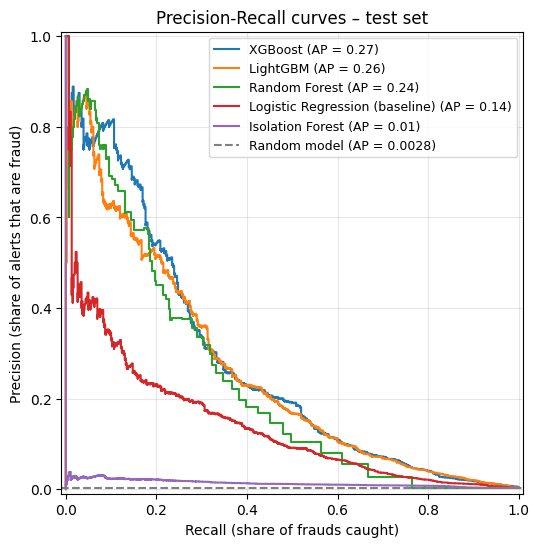

In [0]:
fig, ax = plt.subplots(figsize=(8, 6))

for name in results_df["Model"]:                      # same order as the table
    PrecisionRecallDisplay.from_predictions(y_test, scores[name], name=name, ax=ax)

ax.axhline(y_test.mean(), linestyle="--", color="grey",
           label=f"Random model (AP = {y_test.mean():.4f})")
ax.set_title("Precision-Recall curves – test set")
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

In [0]:
# Conclusion in one sentence, written from the results
best = results_df.iloc[0]
second = results_df.iloc[1]
base_row = results_df[results_df["Model"] == "Logistic Regression (baseline)"].iloc[0]

conclusion = (
    f"The best model is {best['Model']}: it has the highest PR-AUC ({best['PR-AUC']:.4f}), "
    f"{best['PR-AUC'] / base_row['PR-AUC']:.1f}× the Logistic Regression baseline "
    f"and ahead of {second['Model']} ({second['PR-AUC']:.4f})."
    if best["Model"] != "Logistic Regression (baseline)" else
    f"No model beats the Logistic Regression baseline (PR-AUC {best['PR-AUC']:.4f}), so the simpler model is kept."
)

displayHTML(f"<h3>Step 6 – conclusion</h3><p><b>{conclusion}</b></p>")

Step 6 – conclusion The best model is XGBoost: it has the highest PR-AUC (0.2748), 2.0× the Logistic Regression baseline and ahead of LightGBM (0.2570).

## Step 6 – results of the run (test set)

| Model | Precision | Recall | PR-AUC |
|---|---|---|---|
| XGBoost | 0.1029 | 0.6109 | **0.2748** |
| LightGBM | 0.1386 | 0.5522 | 0.2570 |
| Random Forest | 1.0000 | 0.0065 | 0.2378 |
| Logistic Regression (baseline) | 0.0406 | 0.6826 | 0.1405 |
| Isolation Forest | 0.0227 | 0.0261 | 0.0131 |

*Precision and Recall at the 0.5 threshold; Isolation Forest flags the top 0.32% most anomalous transactions.*

**Conclusion: XGBoost is the best model: it has the highest PR-AUC (0.2748, about 2× the Logistic Regression baseline), ahead of LightGBM (0.2570), and at the 0.5 threshold it catches 61% of frauds with about 1 real fraud every 10 alerts.**

# Step 7: final model, threshold and conclusion

- **Model:** XGBoost, the best model in Step 6 (highest PR-AUC). The code takes it from `results_df`, so it follows the table if the ranking changes.
- **Threshold:** we try several values and look at how Precision and Recall move. A low threshold catches more frauds but gives more false alarms; a high one gives fewer, more reliable alerts but misses frauds.
- **How we pick:** the threshold with the best **F1** (the balance between Precision and Recall) among the values tried. Fraud teams can then move it up or down depending on how many alerts they can review.

In [0]:
from sklearn.metrics import ConfusionMatrixDisplay

best_name = results_df.loc[results_df["Model"] != "Isolation Forest", "Model"].iloc[0]
best_scores = scores[best_name]
best_model = {"XGBoost": xgb, "LightGBM": lgbm,
              "Random Forest": rf.named_steps["model"],
              "Logistic Regression (baseline)": baseline.named_steps["model"]}[best_name]
print("Best model:", best_name)

THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rows = []
for t in THRESHOLDS:
    pred = (best_scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "threshold": t,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "alerts": tp + fp, "frauds caught (TP)": tp,
        "false alarms (FP)": fp, "frauds missed (FN)": fn,
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.round(4))

Best model: XGBoost


threshold,Precision,Recall,F1,alerts,frauds caught (TP),false alarms (FP),frauds missed (FN)
0.1,0.0299,0.8239,0.0577,12686,379,12307,81
0.2,0.0484,0.763,0.0911,7250,351,6899,109
0.3,0.0666,0.7152,0.1218,4941,329,4612,131
0.4,0.083,0.6543,0.1474,3625,301,3324,159
0.5,0.1029,0.6109,0.1761,2731,281,2450,179
0.6,0.1232,0.5696,0.2026,2127,262,1865,198
0.7,0.1544,0.5326,0.2394,1587,245,1342,215
0.8,0.2004,0.4696,0.2809,1078,216,862,244
0.9,0.2821,0.3348,0.3062,546,154,392,306


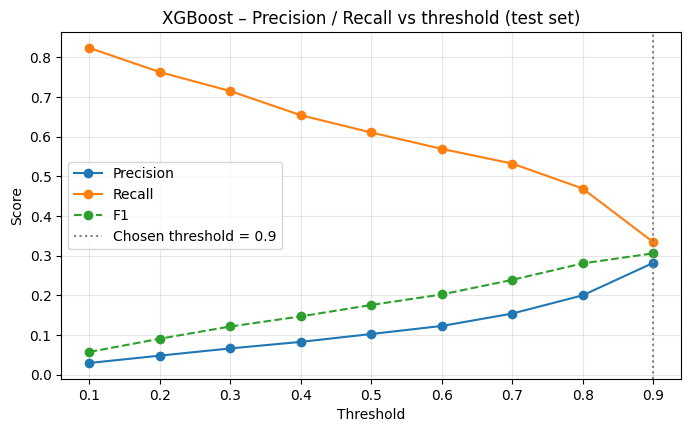

Chosen threshold: 0.9 → Precision 0.282, Recall 0.335, F1 0.306


In [0]:
# Precision and Recall as the threshold moves
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_df["threshold"], threshold_df["Precision"], marker="o", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["Recall"], marker="o", label="Recall")
ax.plot(threshold_df["threshold"], threshold_df["F1"], marker="o", linestyle="--", label="F1")

best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
CHOSEN_THRESHOLD = float(best_row["threshold"])
ax.axvline(CHOSEN_THRESHOLD, color="grey", linestyle=":", label=f"Chosen threshold = {CHOSEN_THRESHOLD}")

ax.set_title(f"{best_name} – Precision / Recall vs threshold (test set)")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(f"Chosen threshold: {CHOSEN_THRESHOLD} → Precision {best_row['Precision']:.3f}, "
      f"Recall {best_row['Recall']:.3f}, F1 {best_row['F1']:.3f}")

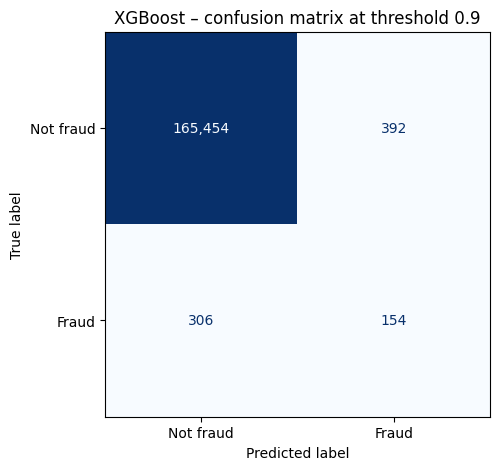

In [0]:
# Confusion matrix at the chosen threshold
y_pred_final = (best_scores >= CHOSEN_THRESHOLD).astype(int)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final,
    display_labels=["Not fraud", "Fraud"],
    values_format=",d", cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title(f"{best_name} – confusion matrix at threshold {CHOSEN_THRESHOLD}")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()

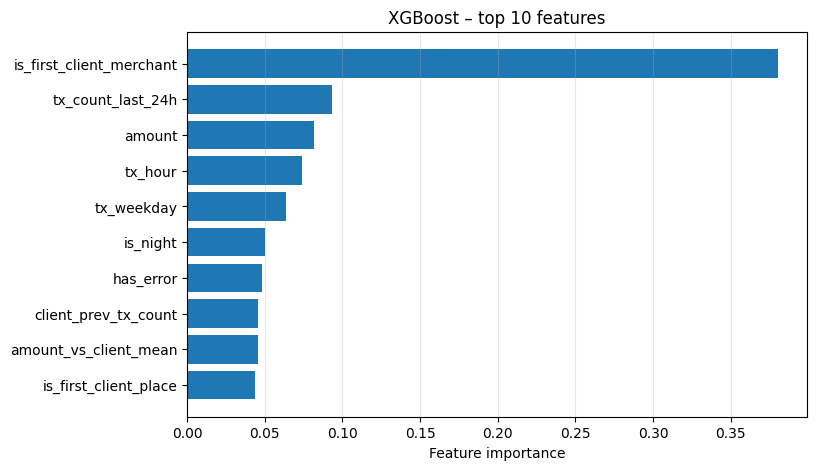

feature,importance
is_first_client_merchant,0.38034147
tx_count_last_24h,0.09322819
amount,0.08158993
tx_hour,0.07363068
tx_weekday,0.06373678
is_night,0.04989249
has_error,0.047986235
client_prev_tx_count,0.04582662
amount_vs_client_mean,0.045410186
is_first_client_place,0.04376036


In [0]:
# Top 10 most important features
if hasattr(best_model, "feature_importances_"):
    importance = best_model.feature_importances_
    label = "Feature importance"
else:                                            # Logistic Regression: size of the coefficient
    importance = np.abs(best_model.coef_[0])
    label = "|coefficient|"

feat_names_best = (rf.named_steps["impute"].get_feature_names_out(MODEL_COLS)
                   if best_name == "Random Forest" else
                   baseline.named_steps["impute"].get_feature_names_out(MODEL_COLS)
                   if best_name.startswith("Logistic") else
                   np.array(MODEL_COLS))

fi = (pd.DataFrame({"feature": feat_names_best, "importance": importance})
        .sort_values("importance", ascending=False)
        .head(10))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fi["feature"][::-1], fi["importance"][::-1])
ax.set_title(f"{best_name} – top 10 features")
ax.set_xlabel(label)
ax.grid(axis="x", alpha=0.3)
plt.show()

display(fi.reset_index(drop=True))

In [0]:
# Conclusion, written from the results above
n_fraud_test = tp + fn
alerts = tp + fp
top3 = ", ".join(f"`{f}`" for f in fi["feature"].head(3))

why = (
    f"Among the thresholds tried, {CHOSEN_THRESHOLD} gives the best balance between catching frauds and "
    f"limiting false alarms (F1 = {f1_score(y_test, y_pred_final):.3f}); "
    f"a lower threshold would raise more alerts, a higher one would miss more frauds."
)

conclusion_7 = f"""
<h3>Step 7 – conclusion</h3>
<p>
The final model is <b>{best_name}</b>, the one with the highest PR-AUC in Step 6
({average_precision_score(y_test, best_scores):.4f}, {average_precision_score(y_test, best_scores) / pr_auc:.1f}× the Logistic Regression baseline).
We use a threshold of <b>{CHOSEN_THRESHOLD}</b>: {why}
On the test set (21 Oct – 31 Dec 2010) it catches <b>{tp:,} of {n_fraud_test:,} frauds ({tp / max(n_fraud_test, 1):.0%})</b>
and misses {fn:,}.
It raises <b>{fp:,} false alarms</b> out of {tn + fp:,} normal transactions ({fp / (tn + fp):.2%}),
so about <b>1 alert in {alerts / max(tp, 1):.0f}</b> is a real fraud.
The most useful signals are {top3}.
</p>
"""
displayHTML(conclusion_7)

Step 7 – conclusion 
 
The final model is XGBoost , the one with the highest PR-AUC in Step 6
(0.2748, 2.0× the Logistic Regression baseline).
We use a threshold of 0.9 : Among the thresholds tried, 0.9 gives the best balance between catching frauds and limiting false alarms (F1 = 0.306); a lower threshold would raise more alerts, a higher one would miss more frauds.
On the test set (21 Oct – 31 Dec 2010) it catches 154 of 460 frauds (33%) 
and misses 306.
It raises 392 false alarms out of 165,846 normal transactions (0.24%),
so about 1 alert in 4 is a real fraud.
The most useful signals are `is_first_client_merchant`, `tx_count_last_24h`, `amount`.

## Step 7 – results of the run (test set)

**Model: XGBoost** (highest PR-AUC in Step 6: 0.2748).

**Precision and Recall at different thresholds**

| Threshold | Precision | Recall | F1 | Alerts | Frauds caught | False alarms | Frauds missed |
|---|---|---|---|---|---|---|---|
| 0.1 | 0.0299 | 0.8239 | 0.0577 | 12,686 | 379 | 12,307 | 81 |
| 0.3 | 0.0666 | 0.7152 | 0.1218 | 4,941 | 329 | 4,612 | 131 |
| 0.5 | 0.1029 | 0.6109 | 0.1761 | 2,731 | 281 | 2,450 | 179 |
| 0.7 | 0.1544 | 0.5326 | 0.2394 | 1,587 | 245 | 1,342 | 215 |
| **0.9** | **0.2821** | **0.3348** | **0.3062** | **546** | **154** | **392** | **306** |

*(The full table with all thresholds from 0.1 to 0.9 is in the output above.)*

Raising the threshold always trades frauds caught for fewer false alarms: from 0.1 to 0.9 Recall falls from 82% to 33%, while false alarms drop from 12,307 to 392.

**Chosen threshold: 0.9.** It has the best F1 among the values tried, and it keeps the alerts to a number a fraud team can actually review: 546 alerts in about 10 weeks, roughly 8 per day. Note that 0.9 is the highest value tested, so a slightly higher threshold could be checked too.

**Confusion matrix at threshold 0.9**

| | Predicted not fraud | Predicted fraud |
|---|---|---|
| **Actual not fraud** | 165,454 (TN) | 392 (FP) |
| **Actual fraud** | 306 (FN) | 154 (TP) |

**Top 10 features (XGBoost importance)**

| # | Feature | Importance |
|---|---|---|
| 1 | `is_first_client_merchant` | 0.380 |
| 2 | `tx_count_last_24h` | 0.093 |
| 3 | `amount` | 0.082 |
| 4 | `tx_hour` | 0.074 |
| 5 | `tx_weekday` | 0.064 |
| 6 | `is_night` | 0.050 |
| 7 | `has_error` | 0.048 |
| 8 | `client_prev_tx_count` | 0.046 |
| 9 | `amount_vs_client_mean` | 0.045 |
| 10 | `is_first_client_place` | 0.044 |

## Conclusion

The final model is **XGBoost**, because it has the highest PR-AUC (0.2748), about twice the Logistic Regression baseline. I chose a **threshold of 0.9**: among the values tried it has the best balance between Precision and Recall (F1 = 0.306), and it produces few enough alerts to be reviewed by a team. With this threshold the model **catches 154 of the 460 frauds** in the test period (33%) and gives **392 false alarms** out of 165,846 normal transactions, so more than 1 alert in 4 is a real fraud, against about 1 in 25 for the baseline. If missing a fraud costs more than checking an alert, the threshold can be lowered to 0.7, which catches 53% of frauds at the price of 1,342 false alarms. By far the strongest signal is a payment at a merchant the client has never used before, followed by the number of transactions in the last 24 hours and the amount.

# Step 8: score every transaction and save `fraud_scores`

- **Model and threshold:** the ones chosen in Step 7 (XGBoost, threshold `CHOSEN_THRESHOLD` = 0.9).
- **Which transactions:** **all** rows of `pay_transactions` (1,240,880), not only the labelled test set. The features are the same Step 2 features, computed only from each client's past.
- **Where:** a **new** Delta table `payments.default.fraud_scores`, in the same schema as the other Client Insider tables. The existing tables are not changed; the scores are joined to them on `transaction_id`.
- **Columns:** `transaction_id`, `fraud_probability` (0–1), `is_flagged` (true/false at the threshold), `model_name`, `scored_at`.
- ⚠️ Transactions up to 21 Oct 2010 were used to **train** the model, so their probabilities are more optimistic than real performance. The honest performance figures are the test-set ones in Step 7.

In [0]:
from datetime import datetime, timezone

SCORES_TABLE = "payments.default.fraud_scores"
MODEL_NAME = {"XGBoost": "xgboost_v1", "LightGBM": "lightgbm_v1",
              "Random Forest": "random_forest_v1",
              "Logistic Regression (baseline)": "logreg_v1"}[best_name]
final_model = {"XGBoost": xgb, "LightGBM": lgbm, "Random Forest": rf,
               "Logistic Regression (baseline)": baseline}[best_name]

# Features for ALL transactions (labelled or not), same columns as in training
X_all_pdf = df_feat.select("id", *MODEL_COLS).toPandas()
X_all = X_all_pdf[MODEL_COLS]
print(f"Transactions to score: {len(X_all):,}")

fraud_probability = final_model.predict_proba(X_all)[:, 1]
scored_at = datetime.now(timezone.utc).replace(microsecond=0)

scores_df = pd.DataFrame({
    "transaction_id": X_all_pdf["id"].astype("int64"),
    "fraud_probability": fraud_probability.astype("float64"),
    "is_flagged": fraud_probability >= CHOSEN_THRESHOLD,
    "model_name": MODEL_NAME,
    "scored_at": pd.Timestamp(scored_at).tz_localize(None),
})

assert scores_df["transaction_id"].is_unique
assert scores_df["fraud_probability"].between(0, 1).all()
print(f"Model: {MODEL_NAME} | threshold: {CHOSEN_THRESHOLD} | scored at (UTC): {scored_at}")
print(f"Flagged: {scores_df['is_flagged'].sum():,} of {len(scores_df):,} ({scores_df['is_flagged'].mean():.2%})")
display(scores_df.head(20))

Transactions to score: 1,240,880
Model: xgboost_v1 | threshold: 0.9 | scored at (UTC): 2026-10-21 17:45:42+00:00
Flagged: 10,922 of 1,240,880 (0.88%)


transaction_id,fraud_probability,is_flagged,model_name,scored_at
8529218,0.005731947720050812,false,xgboost_v1,2026-10-21T17:45:42.000Z
8207513,0.01659809611737728,false,xgboost_v1,2026-10-21T17:45:42.000Z
8207527,0.01088411919772625,false,xgboost_v1,2026-10-21T17:45:42.000Z
8207564,0.009146638214588165,false,xgboost_v1,2026-10-21T17:45:42.000Z
8207583,0.014872806146740913,false,xgboost_v1,2026-10-21T17:45:42.000Z
8208216,0.0036411501932889223,false,xgboost_v1,2026-10-21T17:45:42.000Z
8208624,0.03174380958080292,false,xgboost_v1,2026-10-21T17:45:42.000Z
8208673,0.04143724590539932,false,xgboost_v1,2026-10-21T17:45:42.000Z
8211543,2.067332825390622E-4,false,xgboost_v1,2026-10-21T17:45:42.000Z
8212520,0.0485527366399765,false,xgboost_v1,2026-10-21T17:45:42.000Z


In [0]:
# Write the NEW table fraud_scores (the only table this notebook writes)
existing = [r.tableName for r in spark.sql("SHOW TABLES IN payments.default").collect()]
assert SCORES_TABLE.split(".")[-1] not in {"pay_transactions", "pay_users", "pay_cards", "pay_labels"}

(spark.createDataFrame(scores_df)
      .select(
          F.col("transaction_id").cast("long"),
          F.col("fraud_probability").cast("double"),
          F.col("is_flagged").cast("boolean"),
          F.col("model_name").cast("string"),
          F.col("scored_at").cast("timestamp"),
      )
      .write.mode("overwrite").option("overwriteSchema", "true")
      .saveAsTable(SCORES_TABLE))

spark.sql(f"""COMMENT ON TABLE {SCORES_TABLE} IS
  'Fraud scores per transaction ({MODEL_NAME}, threshold {CHOSEN_THRESHOLD}). Join to pay_transactions.id on transaction_id.'""")

print(f"{SCORES_TABLE} written ({'replaced' if 'fraud_scores' in existing else 'created'})")

payments.default.fraud_scores written (created)


In [0]:
# Checks: every transaction has exactly one score
fs = spark.table(SCORES_TABLE)
tx = spark.table(TX_TABLE)

n_tx, n_fs = tx.count(), fs.count()
n_fs_ids = fs.select("transaction_id").distinct().count()
n_missing = tx.join(fs, tx.id == fs.transaction_id, "left_anti").count()

print(f"pay_transactions rows : {n_tx:,}")
print(f"fraud_scores rows     : {n_fs:,} ({n_fs_ids:,} distinct transaction_id)")
print(f"transactions without a score: {n_missing:,}")
assert n_tx == n_fs == n_fs_ids and n_missing == 0, "Row counts do not match!"
print("✅ Every transaction has exactly one row in fraud_scores")

fs.printSchema()
display(fs.groupBy("model_name", "is_flagged").agg(
    F.count("*").alias("n"),
    F.round(F.avg("fraud_probability"), 4).alias("avg_probability"),
))

pay_transactions rows : 1,240,880
fraud_scores rows     : 1,240,880 (1,240,880 distinct transaction_id)
transactions without a score: 0
✅ Every transaction has exactly one row in fraud_scores
root
 |-- transaction_id: long (nullable = true)
 |-- fraud_probability: double (nullable = true)
 |-- is_flagged: boolean (nullable = true)
 |-- model_name: string (nullable = true)
 |-- scored_at: timestamp (nullable = true)



model_name,is_flagged,n,avg_probability
xgboost_v1,false,1229958,0.0661
xgboost_v1,true,10922,0.949


In [0]:
# Consistency with Step 7: on the test transactions the saved flags must match the confusion matrix
check = (fs.join(spark.createDataFrame(pd.DataFrame({"transaction_id": id_test.astype("int64"),
                                                     "y": y_test.astype(int)})),
                 "transaction_id")
           .agg(F.sum((F.col("is_flagged") & (F.col("y") == 1)).cast("int")).alias("tp"),
                F.sum((F.col("is_flagged") & (F.col("y") == 0)).cast("int")).alias("fp"))
           .first())
print(f"Test set from the table: TP={check.tp}, FP={check.fp} | Step 7: TP={tp}, FP={fp}")
assert (check.tp, check.fp) == (tp, fp)

Test set from the table: TP=154, FP=392 | Step 7: TP=154, FP=392


In [0]:
# Preview of what the dashboard will show: highest-risk transactions and flagged share per client
display(
    fs.join(tx, fs.transaction_id == tx.id)
      .select("transaction_id", "date", "client_id", "amount", "merchant_city",
              "merchant_state", "mcc", F.round("fraud_probability", 4).alias("fraud_probability"),
              "is_flagged")
      .orderBy(F.desc("fraud_probability"))
      .limit(20)
)

display(
    fs.join(tx, fs.transaction_id == tx.id)
      .groupBy("client_id")
      .agg(F.count("*").alias("transactions"),
           F.sum(F.col("is_flagged").cast("int")).alias("flagged"),
           F.round(F.avg(F.col("is_flagged").cast("int")) * 100, 2).alias("flagged_pct"))
      .orderBy(F.desc("flagged"))
      .limit(20)
)

transaction_id,date,client_id,amount,merchant_city,merchant_state,mcc,fraud_probability,is_flagged
8016964,2010-05-17 06:56:00,375,234.66,ONLINE,null,3066,0.9988,true
7767722,2010-03-16 03:22:00,419,686.13,ONLINE,null,5712,0.9985,true
7892110,2010-04-16 05:59:00,1676,111.0,ONLINE,null,3730,0.9984,true
8291306,2010-07-23 05:36:00,615,79.27,ONLINE,null,5912,0.9981,true
7767755,2010-03-16 04:00:00,419,426.0,ONLINE,null,3775,0.9981,true
8262887,2010-07-16 08:33:00,1478,175.23,ONLINE,null,5732,0.9979,true
8062073,2010-05-28 07:27:00,1242,88.21,ONLINE,null,5977,0.9979,true
8563122,2010-09-26 14:08:00,180,280.64,Port au Prince,Haiti,5094,0.9979,true
7989198,2010-05-10 09:05:00,1787,133.5,ONLINE,null,5310,0.9978,true
7910004,2010-04-20 13:54:00,194,135.94,ONLINE,null,5045,0.9978,true


client_id,transactions,flagged,flagged_pct
1696,3770,64,1.7
1190,2102,50,2.38
1147,2383,46,1.93
1989,1644,45,2.74
96,3945,44,1.12
733,1487,43,2.89
1648,2065,42,2.03
1487,1358,40,2.95
1659,2885,37,1.28
285,3243,37,1.14
